In [126]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures, StandardScaler,LabelEncoder
from sklearn.model_selection import train_test_split ,KFold, cross_val_score,GridSearchCV
from sklearn.metrics import (r2_score, mean_squared_error, accuracy_score, confusion_matrix, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay,
    log_loss, classification_report)
from sklearn.tree import DecisionTreeRegressor,DecisionTreeClassifier

In [127]:
df = pd.read_csv('student_performance.csv')
df

,student_id,study_hours_week,attendance_pct,prev_gpa,sleep_hours,assignments_done_pct,part_time_job,final_score,passed
0,S001,11.2,96.4,2.86,6.1,66.9,0,73.5,1
1,S002,5.8,90.7,2.46,6.1,63.0,0,52.9,0
2,S003,13.0,71.4,2.65,8.4,82.8,0,74.2,1
3,S004,13.8,62.0,3.28,7.2,79.5,0,68.2,1
4,S005,2.2,44.4,2.90,6.5,49.7,0,39.9,0
...,...,...,...,...,...,...,...,...,...
495,S496,13.7,84.2,2.24,NaN,100.0,0,65.4,1
496,S497,2.7,89.2,3.09,7.2,72.8,0,52.6,0
497,S498,8.7,81.5,2.21,6.7,35.5,1,53.0,0
498,S499,2.0,81.6,3.33,6.2,65.1,0,50.5,0


In [128]:
## Starting with part A
X = df[['study_hours_week', 'attendance_pct', 'prev_gpa', 'sleep_hours', 'assignments_done_pct', 'part_time_job']]
Y = df['final_score']

In [129]:
## Essential training so the model predicts based on previous data
X_train, X_test, Y_train, Y_test = train_test_split(X , Y, test_size=0.2, random_state=42
)

In [130]:
## clean the data so no error is given since we have NAN in the values
df_clean = df.dropna(subset=['study_hours_week', 'attendance_pct', 'prev_gpa', 'sleep_hours', 'assignments_done_pct', 'part_time_job', 'final_score'])

X_clean = df_clean[['study_hours_week', 'attendance_pct', 'prev_gpa', 'sleep_hours', 'assignments_done_pct', 'part_time_job']]
Y_clean = df_clean['final_score']

# Re split the clean data again
X_train, X_test, Y_train, Y_test = train_test_split(X_clean, Y_clean, test_size=0.2, random_state=42)

mod = LinearRegression()
mod.fit(X_train, Y_train)
Y_pred = mod.predict(X_test)
r2 = r2_score(Y_test, Y_pred)
mse = mean_squared_error(Y_test, Y_pred)
rmse = np.sqrt(mse)
print(f'R2 score: {r2:.2f} , RMSE: {mse:.2f}')


R2 score: 0.67 , RMSE: 37.67


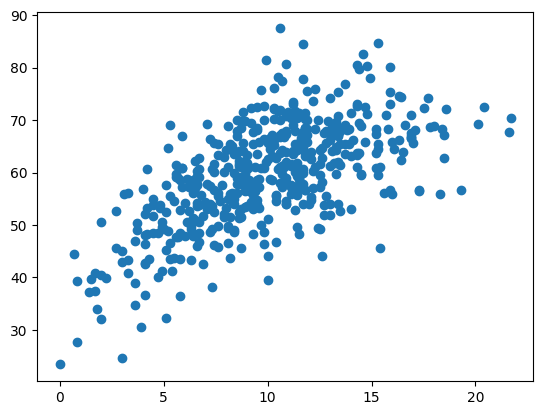

In [131]:
## Plotting to check if the 20th hour has as much effect as the 2nd hour
plt.scatter(df['study_hours_week'],df['final_score'])

In [132]:
# We'll test from range 1 to 6 and make an empty array to store the degree values in
degrees = range(1, 6)
scores_tried = []

# Using the 5-fold cross validation
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for degree in degrees:
    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X_clean)
    model = LinearRegression()
    neg_mse_scores = cross_val_score(model, X_poly, Y_clean, scoring='neg_mean_squared_error', cv=kfold)

  # added the negative so we can convert it to positive and
    avg_mse = -np.mean(neg_mse_scores)
    avg_rmse = np.sqrt(avg_mse)

    scores_tried.append(avg_rmse)
    print(f"Degree {degree} - CV RMSE: {avg_rmse:.4f}")

# the best degree will have the smallest rmse
best_degree = degrees[np.argmin(scores_tried)]
print(f"The best degree will be  {best_degree}")



Degree 1 - CV RMSE: 5.6601
Degree 2 - CV RMSE: 5.1472
Degree 3 - CV RMSE: 5.8670
Degree 4 - CV RMSE: 11.1332
Degree 5 - CV RMSE: 245.0668
The best degree will be  2


In [133]:
## Polynomial Regression
poly = PolynomialFeatures(degree=2)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.fit_transform(X_test)
mod_poly = LinearRegression()
mod_poly.fit(X_train_poly, Y_train)
Y_pred_poly = mod_poly.predict(X_test_poly)
r2_poly = r2_score(Y_test, Y_pred_poly)
mse = mean_squared_error(Y_test, Y_pred_poly)
rmse = np.sqrt(mse)
print(f'R2 score: {r2_poly:.2f} , RMSE: {mse:.2f}')

R2 score: 0.74 , RMSE: 29.01


In [134]:
## Now we make the Y passed colomun since we are classifying
X_clean_class = df_clean[['study_hours_week', 'attendance_pct', 'prev_gpa', 'sleep_hours', 'assignments_done_pct', 'part_time_job']]
Y_clean_class = df_clean['passed']

X_train_c, X_test_c, Y_train_c, Y_test_c = train_test_split(X_clean_class, Y_clean_class, test_size=0.2, random_state=42)

# Then we Scale the cleaned features
scaler = StandardScaler()
X_train_scaled= scaler.fit_transform(X_train_c)
X_test_scaled= scaler.transform(X_test_c)

In [135]:

# Logistic Regression and predict
mod_log = LogisticRegression(random_state = 42)
mod_log.fit(X_train_scaled, Y_train_c)
Y_pred_log = mod_log.predict(X_test_scaled)
accuracy = accuracy_score(Y_test_c, Y_pred_log)
precision = precision_score(Y_test_c, Y_pred_log)
recall = recall_score(Y_test_c, Y_pred_log)
f1 = f1_score(Y_test_c, Y_pred_log)
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1 Score:  {f1:.2f}\n")
cm = confusion_matrix(Y_test_c, Y_pred_log)
print(cm)


Accuracy:  0.85
Precision: 0.88
Recall:    0.93
F1 Score:  0.90

[[16  9]
 [ 5 65]]


In [136]:
# Trying to get the best depth first
depths = range(1, 8)
cv_scores = []

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for depth in depths:
    tree_model = DecisionTreeClassifier(max_depth=depth, random_state=42)
    scores = cross_val_score(tree_model, X_train_scaled, Y_train_c, scoring='accuracy', cv=kfold)
    mean_acc = np.mean(scores)
    cv_scores.append(mean_acc)
    print(f"Max Depth: {depth} Accuracy: {mean_acc:.2f}")

best_depth = depths[np.argmax(cv_scores)]
print(f" The best depth is  {best_depth} ")
## gridsearch
print("Gridsearch Value")
param_grid = {'max_depth': range(1, 8)}
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=5)
grid_search.fit(X_train_scaled, Y_train_c)
best_depth = grid_search.best_params_['max_depth']
print(f"The best depth is {best_depth} ")


Max Depth: 1 Accuracy: 0.79
Max Depth: 2 Accuracy: 0.79
Max Depth: 3 Accuracy: 0.81
Max Depth: 4 Accuracy: 0.79
Max Depth: 5 Accuracy: 0.82
Max Depth: 6 Accuracy: 0.80
Max Depth: 7 Accuracy: 0.81
 The best depth is  5 
Gridsearch Value
The best depth is 5 


In [137]:
# decsion tree
mod_tree = DecisionTreeClassifier(random_state = 42)
mod_tree.fit(X_train_scaled, Y_train_c)
Y_pred_tree = mod_tree.predict(X_test_scaled)
accuracy = accuracy_score(Y_test_c, Y_pred_tree)
precision = precision_score(Y_test_c, Y_pred_tree)
recall = recall_score(Y_test_c, Y_pred_tree)
f1 = f1_score(Y_test_c, Y_pred_tree)
print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1 Score:  {f1:.2f}\n")
cm = confusion_matrix(Y_test_c, Y_pred_tree)
print(cm)

Accuracy:  0.84
Precision: 0.92
Recall:    0.86
F1 Score:  0.89

[[20  5]
 [10 60]]


In [138]:
# check the best K using 5-fold cross validation
k_values = range(1, 12)
cv_scores = []

kfold = KFold(n_splits=5, shuffle=True, random_state=42)

for k in k_values:
    knn_model = KNeighborsClassifier(n_neighbors=k)

    scores = cross_val_score(knn_model, X_train_scaled, Y_train_c, scoring='accuracy', cv=kfold)
    mean_acc = np.mean(scores)
    cv_scores.append(mean_acc)
    print(f"K = {k} - Accuracy: {mean_acc:.2f}")

best_k = k_values[np.argmax(cv_scores)]
print(f"\nThe best K is: {best_k} (Accuracy: {max(cv_scores):.4f})")

# making a gridsearch
param_grid = {'n_neighbors': range(1, 12)}
grid_search = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5)
grid_search.fit(X_train_scaled, Y_train_c)
best_k = grid_search.best_params_['n_neighbors']
print(f"The best K is: {best_k} (Accuracy: {grid_search.best_score_:.4f})")

K = 1 - Accuracy: 0.76
K = 2 - Accuracy: 0.75
K = 3 - Accuracy: 0.81
K = 4 - Accuracy: 0.80
K = 5 - Accuracy: 0.80
K = 6 - Accuracy: 0.80
K = 7 - Accuracy: 0.80
K = 8 - Accuracy: 0.82
K = 9 - Accuracy: 0.78
K = 10 - Accuracy: 0.80
K = 11 - Accuracy: 0.78

The best K is: 8 (Accuracy: 0.8165)
The best K is: 10 (Accuracy: 0.8032)


In [139]:
# using knn after finding the best k make sure it's scaled
knn = KNeighborsClassifier(n_neighbors=8)
knn.fit(X_train_scaled, Y_train_c)
Y_pred_knn = knn.predict(X_test_scaled)


accuracy = accuracy_score(Y_test_c, Y_pred_knn)
precision = precision_score(Y_test_c, Y_pred_knn)
recall = recall_score(Y_test_c, Y_pred_knn)
f1 = f1_score(Y_test_c, Y_pred_knn)

print(f"Accuracy:  {accuracy:.2f}")
print(f"Precision: {precision:.2f}")
print(f"Recall:    {recall:.2f}")
print(f"F1 Score:  {f1:.2f}\n")

cm = confusion_matrix(Y_test_c, Y_pred_knn)
print(cm)

Accuracy:  0.85
Precision: 0.88
Recall:    0.93
F1 Score:  0.90

[[16  9]
 [ 5 65]]


In [140]:
## Compare all classes made accuracy , prec , recall and f1 for the linears aswell so it's a fair comaprison among all
def get_class_metrics(model, X_test, Y_test):
    Y_pred = model.predict(X_test)
    return {
        'Accuracy': accuracy_score(Y_test, Y_pred),
        'Precision': precision_score(Y_test, Y_pred),
        'Recall': recall_score(Y_test, Y_pred),
        'F1 Score': f1_score(Y_test, Y_pred)
    }


def get_reg_as_class_metrics(model, X_test, Y_test_binary, is_poly=False):
    if is_poly:

        X_test_transformed = poly.transform(X_test)
        Y_pred_continuous = model.predict(X_test_transformed)
    else:
        Y_pred_continuous = model.predict(X_test)


    Y_pred_binary = (Y_pred_continuous >= 50).astype(int)
    return {
        'Accuracy': accuracy_score(Y_test_binary, Y_pred_binary),
        'Precision': precision_score(Y_test_binary, Y_pred_binary),
        'Recall': recall_score(Y_test_binary, Y_pred_binary),
        'F1 Score': f1_score(Y_test_binary, Y_pred_binary)
    }

comparison_data = {
    'Linear Regression (Thresholded)': get_reg_as_class_metrics(mod, X_test, Y_test_c, is_poly=False),
    'Polynomial Regression (Thresholded)': get_reg_as_class_metrics(mod_poly, X_test, Y_test_c, is_poly=True),
    'Logistic Regression': get_class_metrics(mod_log, X_test_scaled, Y_test_c),
    'Decision Tree (depth=5)': get_class_metrics(mod_tree, X_test_scaled, Y_test_c),
    'KNN (K=8)': get_class_metrics(knn, X_test_scaled, Y_test_c)
}


df_compare = pd.DataFrame(comparison_data).T

display(df_compare.round(3))

,Accuracy,Precision,Recall,F1 Score
Linear Regression (Thresholded),0.821,0.805,1.000,0.892
Polynomial Regression (Thresholded),0.832,0.814,1.000,0.897
Logistic Regression,0.853,0.878,0.929,0.903
Decision Tree (depth=5),0.842,0.923,0.857,0.889
KNN (K=8),0.853,0.878,0.929,0.903
